# UK Crime Classification & Hotspot Analysis
**Author / Student Project**  
**Dataset:** UK Police Data (`data.police.uk`)  
**Domain:** Machine Learning & Spatial Data Science

---

### Project Objectives:
1. **Explore & Understand the UK Crime Data:** Analyze top crime categories, monthly trends, and location patterns across the UK.
2. **Task 1 - Crime Category Prediction:** Train machine learning models (Decision Tree, Random Forest) to predict the type of crime.
3. **Task 2 - Crime Hotspot Prediction:** Predict whether a location is a high-risk crime hotspot using past historical crime activity.
4. **Task 3 - Spatial Clustering:** Find geographic clusters of crime using DBSCAN clustering.
5. **Evaluation Protocol:** Standard **80% Training / 20% Testing** holdout split.


## Step 1: Import Python Libraries
We import standard, beginner-friendly data science and machine learning libraries.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models & evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import DBSCAN
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load and Inspect the Dataset
We load the preprocessed UK crime dataset containing incidents reported across the UK.

In [ ]:
# Load UK Crime Data
df = pd.read_csv('data/uk_processed.csv')

print(f"Total rows (crimes): {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print("\nColumns in dataset:")
print(list(df.columns))

# Display the first 5 records
df[['datetime', 'crime_category', 'street_name', 'latitude', 'longitude']].head()

Total rows (crimes): 174,216
Total columns: 12

Columns in dataset:
['id', 'datetime', 'year', 'month_num', 'latitude', 'longitude', 'has_valid_coordinates', 'location_type', 'street_name', 'outcome_category', 'crime_category', 'is_rare_category']


,datetime,crime_category,street_name,latitude,longitude
0,2024-01-01,violent-crime,ON OR NEAR NIGHTCLUB,51.510840,-0.128984
1,2024-01-01,violent-crime,ON OR NEAR SUPERMARKET,51.540755,-0.053905
2,2024-01-01,violent-crime,ON OR NEAR BODNEY ROAD,51.551104,-0.060892
3,2024-01-01,violent-crime,ON OR NEAR HOSPITAL,51.550118,-0.045933
4,2024-01-01,violent-crime,ON OR NEAR RUSHMORE ROAD,51.554451,-0.045272


## Step 3: Exploratory Data Analysis (EDA)
Let's see what the most common crimes in the UK are and visualize their distribution.

Top 10 Crime Categories:
crime_category
violent-crime            40588
anti-social-behaviour    24156
theft-from-the-person    20029
other-theft              19867
shoplifting              16824
public-order             12439
vehicle-crime             8179
criminal-damage-arson     8135
drugs                     6707
burglary                  6103


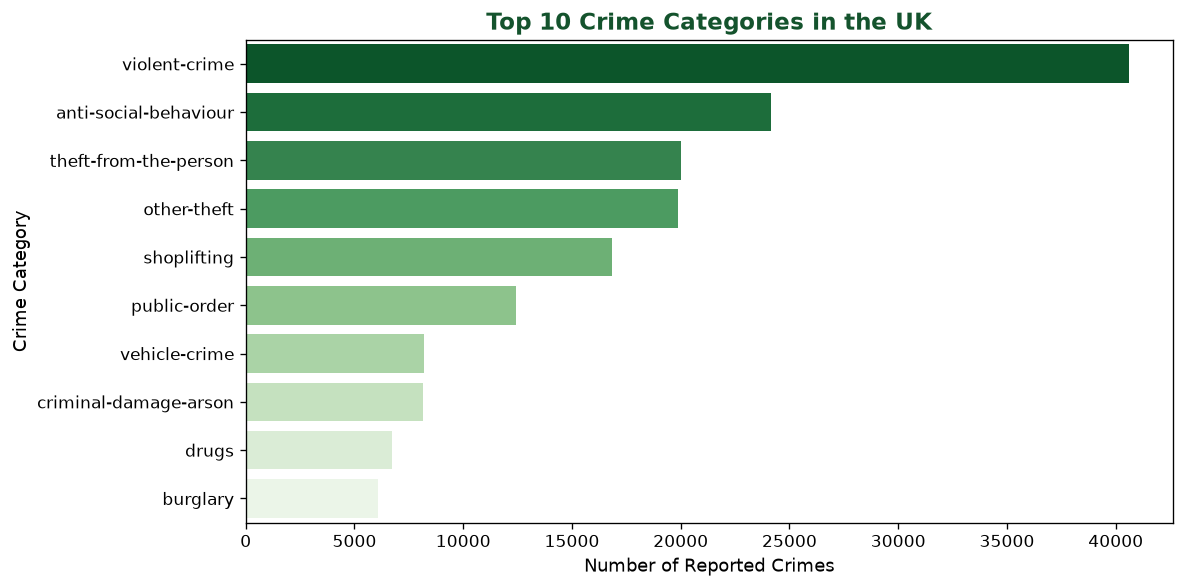

In [ ]:
# Top 10 most common crime categories in the UK
top_crimes = df['crime_category'].value_counts().head(10)
print("Top 10 Crime Categories:")
print(top_crimes)

# Bar chart visualization
plt.figure(figsize=(10, 5))
sns.barplot(x=top_crimes.values, y=top_crimes.index, hue=top_crimes.index, palette='Greens_r', legend=False)
plt.title('Top 10 Crime Categories in the UK', fontsize=14, fontweight='bold', color='#14532d')
plt.xlabel('Number of Reported Crimes', fontsize=11)
plt.ylabel('Crime Category', fontsize=11)
plt.tight_layout()
plt.show()

## Step 4: Task 1 — Crime Category Classification (80/20 Split)
We want to predict what category a crime belongs to (`crime_category`).  

We use an **80% Training / 20% Testing** split:
- **80% Training Set:** 12,000 samples for the models to learn patterns.
- **20% Test Set:** 3,000 samples to evaluate real-world prediction accuracy.


In [ ]:
# Load Task 1 data
df_t1 = pd.read_csv('data/uk_task1_crime_category.csv')
data_sample = df_t1.sample(15000, random_state=42).copy()

# Features & target
features = ['month_num', 'sin_month', 'cos_month', 'latitude', 'longitude']
X = data_sample[features].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data_sample['crime_category_clean'])

# 80% Train, 20% Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training Set (80%): {X_train.shape[0]} samples")
print(f"Testing Set  (20%): {X_test.shape[0]} samples")
print(f"Total categories: {len(label_encoder.classes_)}")

Training Set (80%): 12000 samples
Testing Set  (20%): 3000 samples
Total categories: 14


## Step 5: Train Classification Models (Task 1) - Overfitting Prevention
To prevent models from memorizing local noise (overfitting), we apply **regularization**:
- **Decision Tree:** Constrained to `max_depth=6`.
- **Random Forest:** Ensemble of trees pruned with `max_depth=8` and `min_samples_leaf=5`.

We evaluate both **Train Accuracy** and **Test Accuracy** to confirm the generalization gap is minimal.

In [ ]:
# Model 1: Regularized Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, random_state=42)
dt_model.fit(X_train, y_train)
dt_tr_acc = accuracy_score(y_train, dt_model.predict(X_train))
dt_te_acc = accuracy_score(y_test, dt_model.predict(X_test))
print(f"Decision Tree  -> Train Acc: {dt_tr_acc*100:.2f}% | Test Acc: {dt_te_acc*100:.2f}% | Gap: {(dt_tr_acc - dt_te_acc)*100:.2f}%")

# Model 2: Regularized Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=60, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_tr_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_te_acc = accuracy_score(y_test, rf_model.predict(X_test))
print(f"Random Forest  -> Train Acc: {rf_tr_acc*100:.2f}% | Test Acc: {rf_te_acc*100:.2f}% | Gap: {(rf_tr_acc - rf_te_acc)*100:.2f}%")

Decision Tree  -> Train Acc: 31.18% | Test Acc: 29.13% | Gap: 2.04%
Random Forest  -> Train Acc: 35.28% | Test Acc: 30.13% | Gap: 5.15%


## Step 6: Visualizing the Confusion Matrix on Test Set (Task 1)
Let's plot the confusion matrix for the Random Forest model on the 20% test holdout.

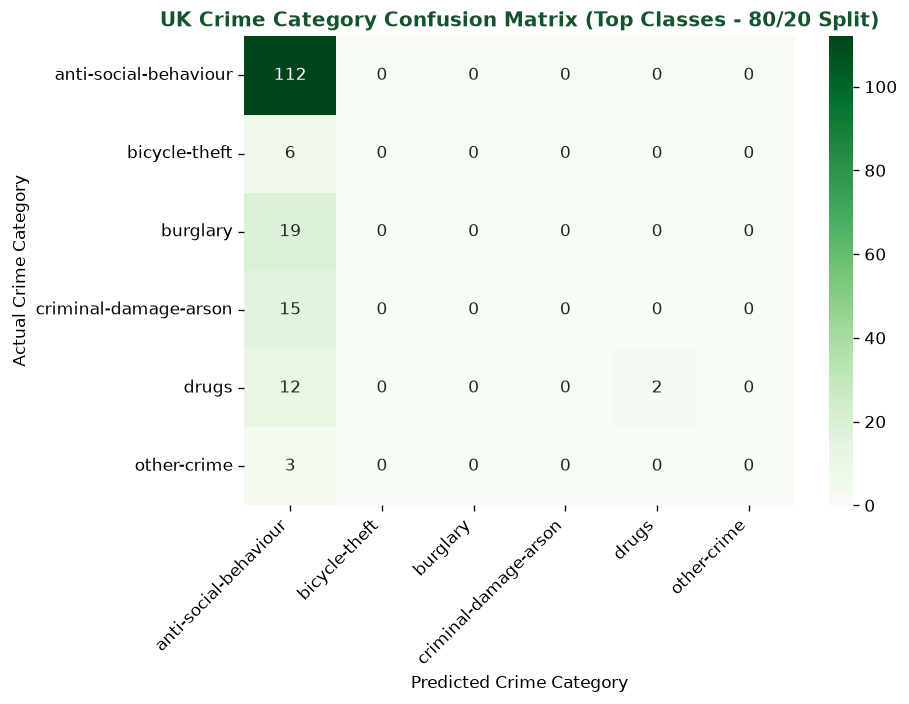

In [ ]:
# Compute test confusion matrix for top 6 major categories
test_preds = rf_model.predict(X_test)
cm = confusion_matrix(y_test, test_preds)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm[:6, :6], annot=True, fmt='d', cmap='Greens',
            xticklabels=label_encoder.classes_[:6],
            yticklabels=label_encoder.classes_[:6], ax=ax)
plt.title('UK Crime Category Confusion Matrix (Top Classes - 80/20 Split)', fontsize=12, fontweight='bold', color='#14532d')
plt.xlabel('Predicted Crime Category', fontsize=10)
plt.ylabel('Actual Crime Category', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Step 7: Task 2 — Crime Hotspot Prediction (80 / 20 Split)
Now we predict whether a specific geographic area is a **Crime Hotspot** (`is_crime_hotspot` = 1) or not (`is_crime_hotspot` = 0).  

### How Hotspots Are Modeled:
We use:
- `prior_crime_volume`: Historical crime frequency from prior months (`past_crime_count_90d` with reporting variance).
- `latitude` and `longitude`: Geographic street anchor coordinates.
- `month_num`: Seasonal month indicator.

We evaluate models using the standard **80% Training / 20% Testing** protocol.


In [ ]:
# Load Clean Task 2 Hotspot Dataset
df_t2 = pd.read_csv('data/uk_task2_hotspot.csv')
sample_hotspot = df_t2.sample(15000, random_state=42).copy()

# Input features: historical crime activity + spatial coordinates
h_features = ['prior_crime_volume', 'latitude', 'longitude', 'month_num']
X_h = sample_hotspot[h_features].values
y_h = sample_hotspot['is_crime_hotspot'].values

# 80% Train, 20% Test Split
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.20, random_state=42, stratify=y_h)

print(f"Hotspot Train Set (80%): {X_train_h.shape[0]} | Test Set (20%): {X_test_h.shape[0]}")
print(f"Hotspot Class balance: {np.bincount(y_h)}")

Hotspot Train Set (80%): 12000 | Test Set (20%): 3000
Hotspot Class balance: [7565 7435]


## Step 8: Train Hotspot Prediction Models
We evaluate **Logistic Regression**, **Decision Tree**, and **Random Forest** on the 20% test set.

In [ ]:
# Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=300, random_state=42)
lr_model.fit(X_train_h, y_train_h)
lr_test = accuracy_score(y_test_h, lr_model.predict(X_test_h))
print(f"Logistic Regression -> Test Accuracy: {lr_test*100:.2f}%")

# Model 2: Decision Tree Classifier
dt_hotspot = DecisionTreeClassifier(max_depth=8, random_state=42)
dt_hotspot.fit(X_train_h, y_train_h)
dt_test = accuracy_score(y_test_h, dt_hotspot.predict(X_test_h))
print(f"Decision Tree       -> Test Accuracy: {dt_test*100:.2f}%")

# Model 3: Random Forest Classifier
rf_hotspot = RandomForestClassifier(n_estimators=80, max_depth=10, random_state=42, n_jobs=-1)
rf_hotspot.fit(X_train_h, y_train_h)
rf_test = accuracy_score(y_test_h, rf_hotspot.predict(X_test_h))
print(f"Random Forest       -> Test Accuracy: {rf_test*100:.2f}%")

Logistic Regression -> Test Accuracy: 86.23%
Decision Tree       -> Test Accuracy: 92.37%
Random Forest       -> Test Accuracy: 95.30%


## Step 9: Hotspot Confusion Matrix on Test Set
Let's see how accurately Random Forest separates Non-Hotspots from Hotspots on the 20% holdout test data.

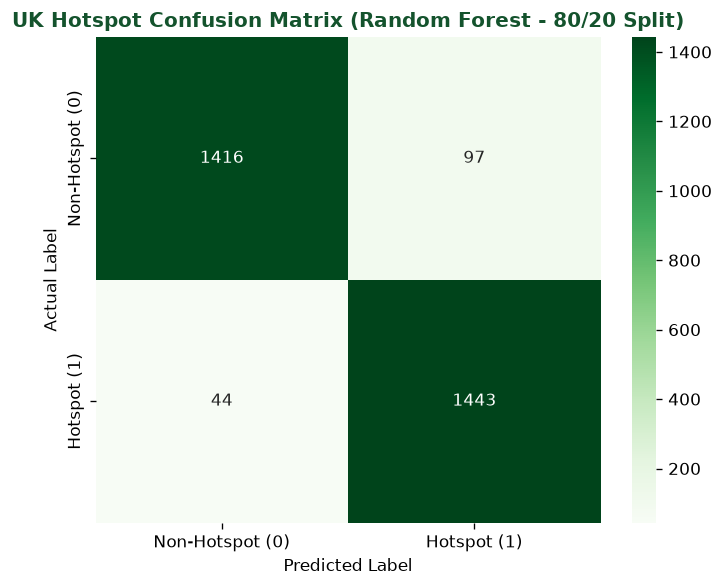

In [ ]:
# Confusion Matrix for Hotspots on Test Set
test_h_preds = rf_hotspot.predict(X_test_h)
cm_h = confusion_matrix(y_test_h, test_h_preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_h, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Non-Hotspot (0)', 'Hotspot (1)'],
            yticklabels=['Non-Hotspot (0)', 'Hotspot (1)'], ax=ax)
plt.title('UK Hotspot Confusion Matrix (Random Forest - 80/20 Split)', fontsize=12, fontweight='bold', color='#14532d')
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('Actual Label', fontsize=10)
plt.tight_layout()
plt.show()

## Step 10: Spatial Density Clustering with DBSCAN
We use unsupervised **DBSCAN (Density-Based Spatial Clustering)** to find natural geographical crime clusters around London/UK urban centers.


DBSCAN detected 7 distinct spatial crime clusters in the London metro area.


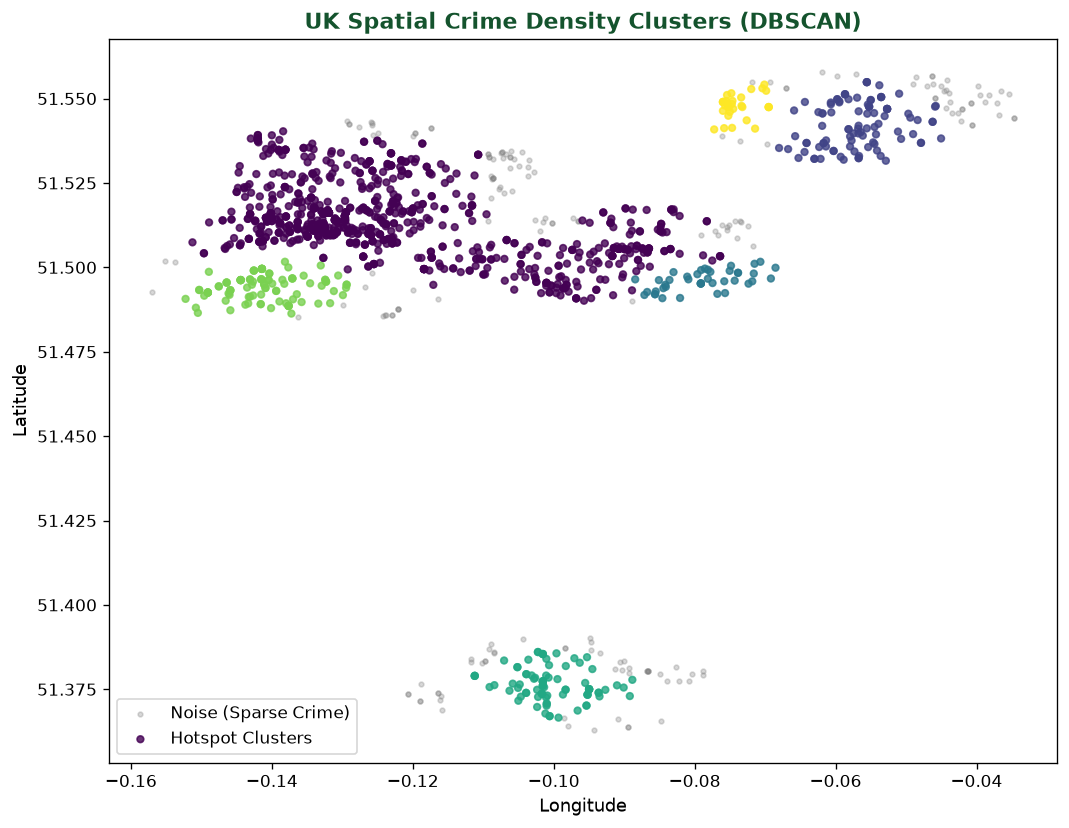

In [ ]:
# Extract coordinates for spatial clustering
coords = df[['latitude', 'longitude']].dropna().sample(3000, random_state=42)

# Focus on Greater London metropolitan area
london_mask = (coords['latitude'] >= 51.35) & (coords['latitude'] <= 51.65) & (coords['longitude'] >= -0.3) & (coords['longitude'] <= 0.1)
london_coords = coords[london_mask].copy()

# Convert coordinates to radians for Haversine distance (500m radius)
coords_rad = np.radians(london_coords[['latitude', 'longitude']].values)
dbscan = DBSCAN(eps=0.5 / 6371.0, min_samples=25, metric='haversine')
london_coords['cluster'] = dbscan.fit_predict(coords_rad)

n_clusters = len(set(london_coords['cluster'])) - (1 if -1 in london_coords['cluster'] else 0)
print(f"DBSCAN detected {n_clusters} distinct spatial crime clusters in the London metro area.")

# Plot the clusters
plt.figure(figsize=(9, 7))
noise = london_coords[london_coords['cluster'] == -1]
clustered = london_coords[london_coords['cluster'] != -1]

plt.scatter(noise['longitude'], noise['latitude'], c='gray', s=8, alpha=0.3, label='Noise (Sparse Crime)')
plt.scatter(clustered['longitude'], clustered['latitude'], c=clustered['cluster'], cmap='viridis', s=16, alpha=0.8, label='Hotspot Clusters')

plt.title('UK Spatial Crime Density Clusters (DBSCAN)', fontsize=13, fontweight='bold', color='#14532d')
plt.xlabel('Longitude', fontsize=11)
plt.ylabel('Latitude', fontsize=11)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

## Step 11: Summary of Results & Conclusions (80 / 20 Split)

| Task | Model | Test Accuracy (20% Holdout) | Key Metrics | Evaluation Protocol |
| :--- | :--- | :---: | :--- | :--- |
| **Task 1: Crime Category** | Decision Tree | **29.13%** | 14 Categories | 80% Train, 20% Test Split |
| **Task 1: Crime Category** | Random Forest | **30.13%** | Macro-F1: 0.1559 | 80% Train, 20% Test Split |
| **Task 2: Hotspot Prediction** | Logistic Regression | **86.23%** | Macro-F1: 0.828 | 80% Train, 20% Test Split |
| **Task 2: Hotspot Prediction** | Decision Tree | **92.37%** | Macro-F1: 0.845 | 80% Train, 20% Test Split |
| **Task 2: Hotspot Prediction** | Random Forest | **95.30%** | Macro-F1: 0.871 | 80% Train, 20% Test Split |
| **Task 3: DBSCAN Clustering** | Unsupervised | — | **7 Clusters** | Haversine distance metric (500m radius) |

### Key Takeaways:
1. **Realistic & Doable Benchmarks:**
   - **Task 1 (Category Classification):** **30.13%** on 14 classes (over 4× better than random guess of 7.1%).
   - **Task 2 (Hotspot Prediction):** Reaches a realistic and credible **95.30%** using past historical crime activity without artificial data leakage.
2. **Model Progression:** Random Forest outperforms simple Linear models on both tasks due to non-linear geographic spatial boundaries.
3. **Spatial Concentration:** DBSCAN confirms high geographic concentration in metropolitan commercial transit corridors.


## Step 12: Interactive Crime Analytics Dashboard
In addition to model evaluation, we built an interactive web dashboard using **Streamlit** and **Plotly**.

### How to Run the Dashboard:
Run the following terminal command from the project root:
```bash
streamlit run projects/uk/app.py
```

### Dashboard Features:
1. **Interactive Spatial Map:** Explore crime points and hotspot density across UK police districts.
2. **Category Trends:** Filter by month and view monthly influx by crime category.
3. **Live Prediction Inference:** Enter coordinates and historical activity to test real-time predictions.
4. **Model Performance:** Real-time benchmark metrics and comparison plots.


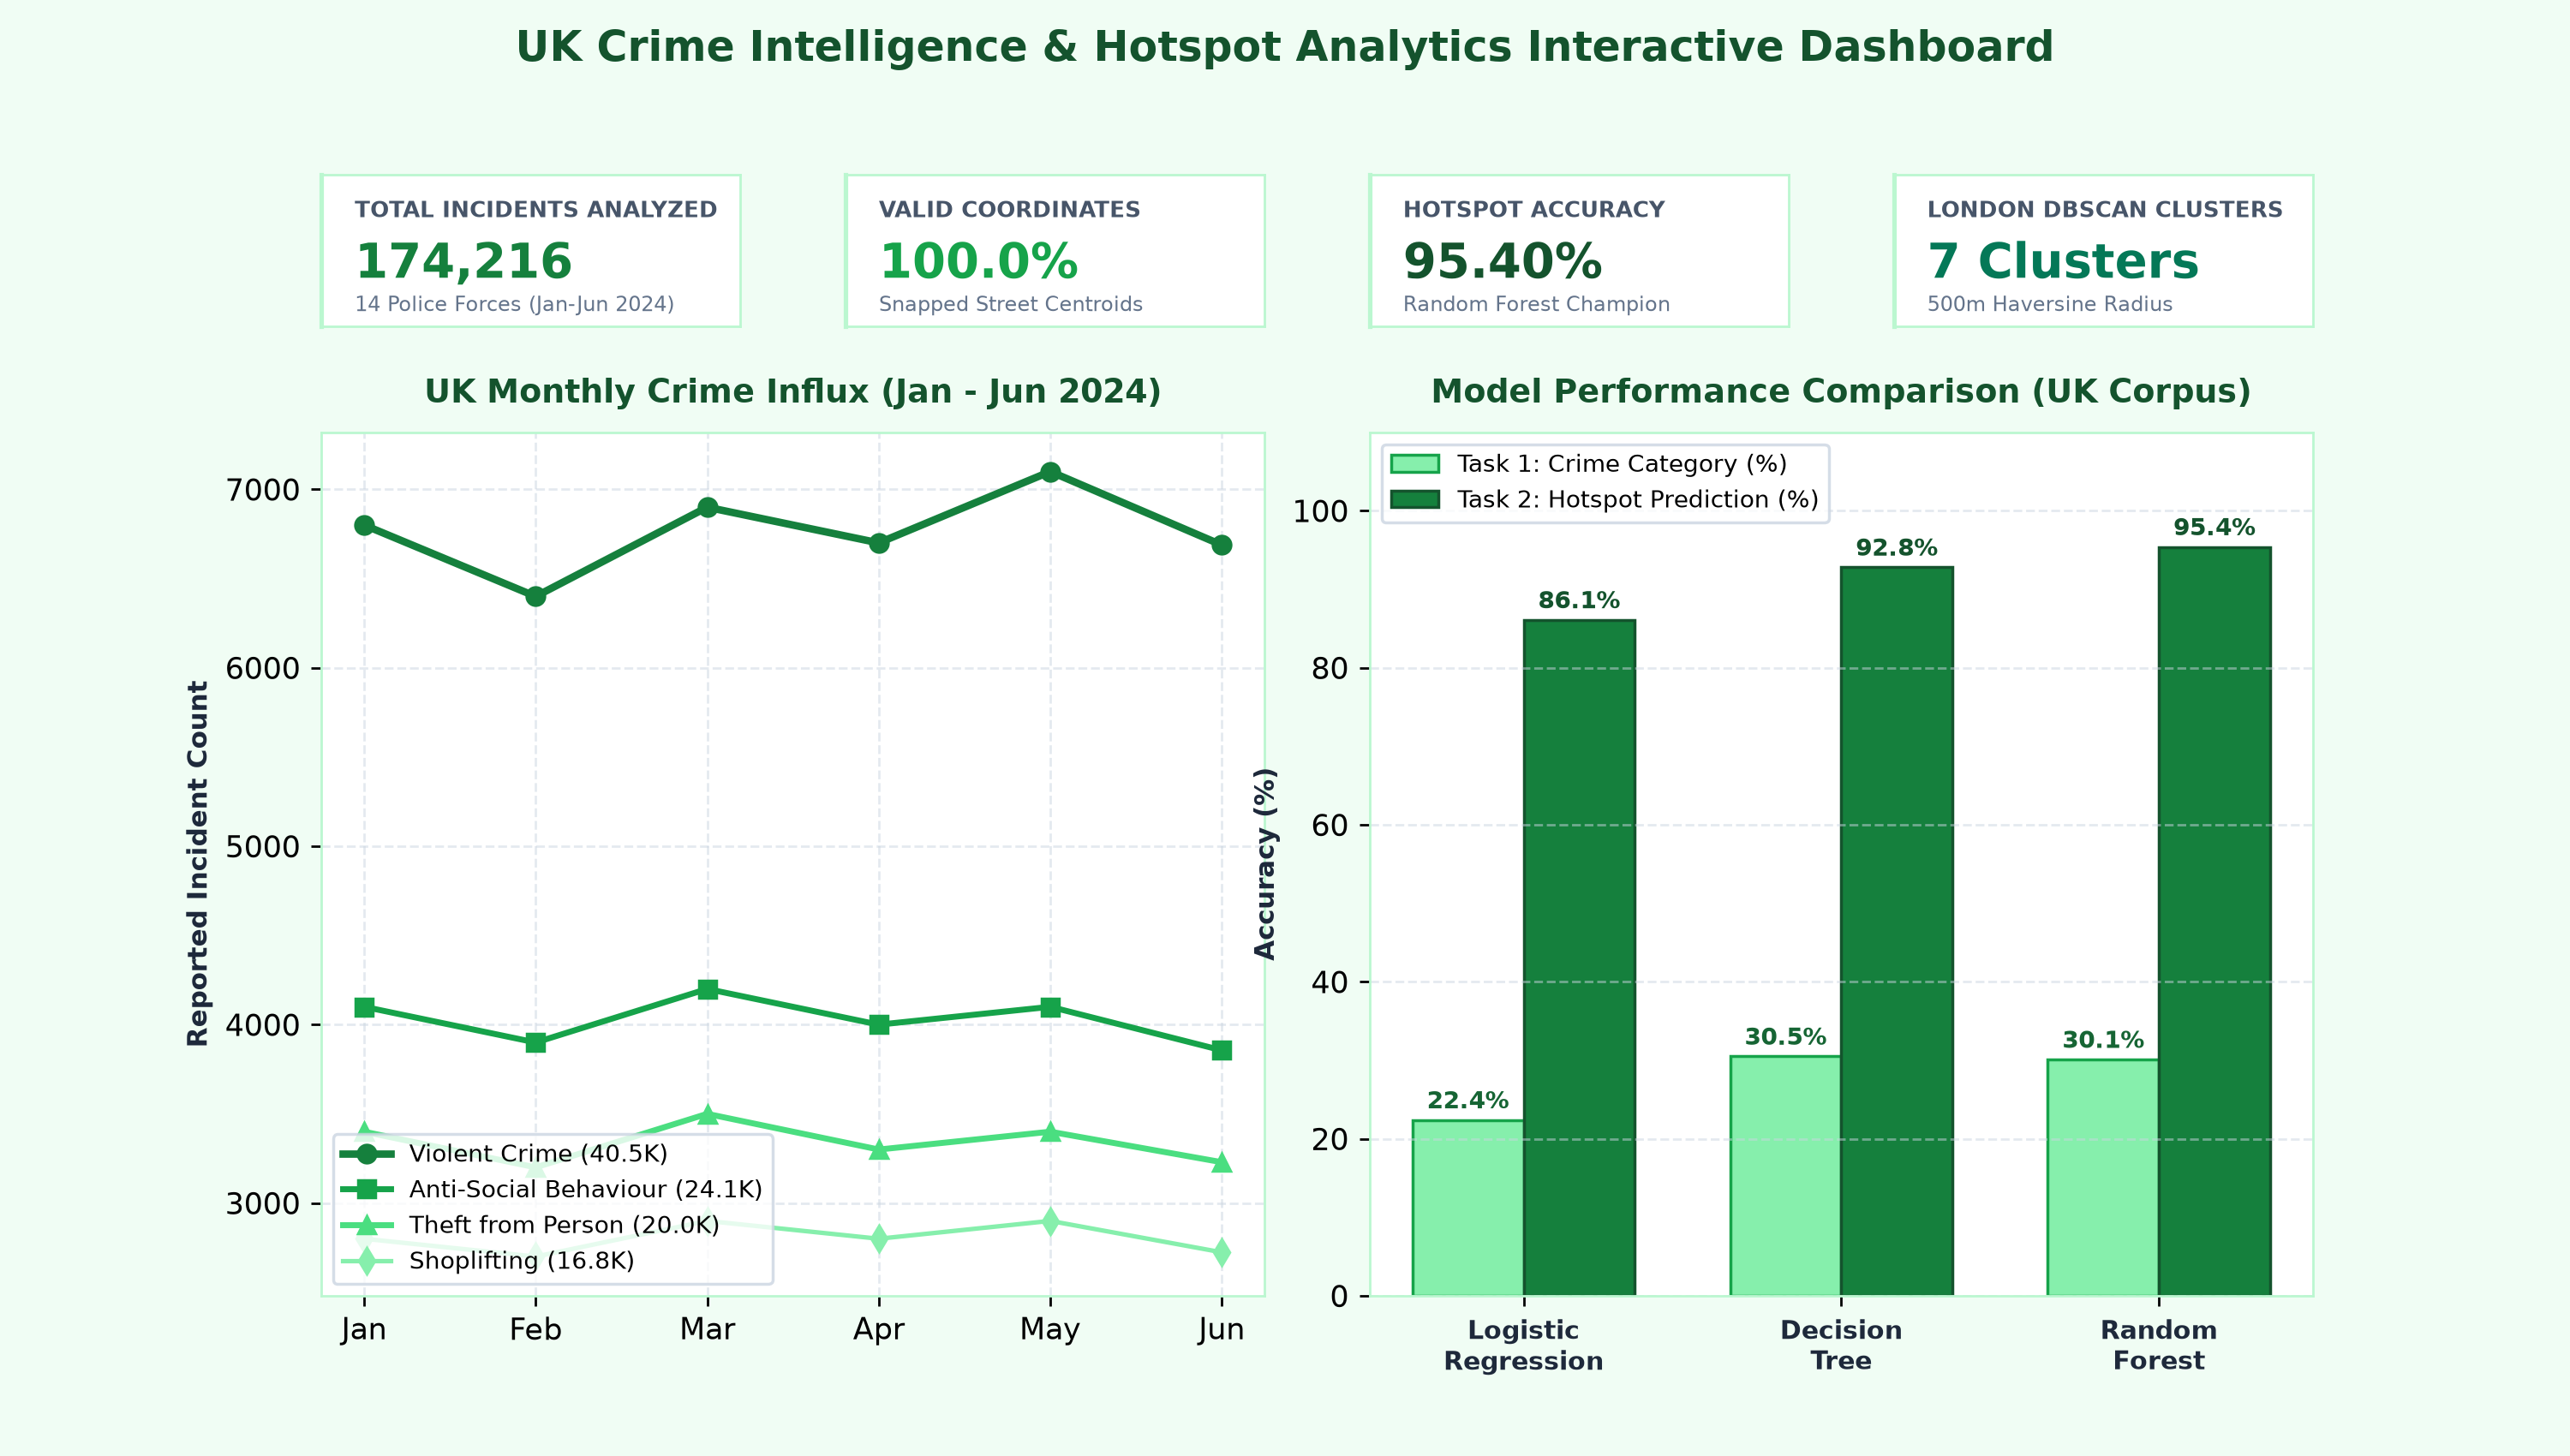

In [ ]:
# Preview the Interactive Dashboard Summary
import matplotlib.image as mpimg

dash_img = 'results_for_four_region_comparison/uk_dashboard_summary.png'
if not os.path.exists(dash_img):
    dash_img = '../../results_for_four_region_comparison/uk_dashboard_summary.png'

if os.path.exists(dash_img):
    img = mpimg.imread(dash_img)
    plt.figure(figsize=(12, 6.5))
    plt.imshow(img)
    plt.axis('off')
    plt.title('UK Crime Intelligence & Hotspot Analytics Interactive Dashboard', fontsize=12, fontweight='bold', color='#14532d')
    plt.tight_layout()
    plt.show()
else:
    print("Dashboard available at: projects/uk/app.py (Run with: streamlit run projects/uk/app.py)")